# EA3 – Aprendizaje supervisado y no supervisado

## 1. Pregunta de negocio

**¿Qué hábitos de alimentación y de actividad física permiten identificar a las personas con obesidad, para que una EPS priorice a quién incluir en sus programas de prevención y acompañamiento nutricional?**

- **Quién necesita la respuesta:** el área de promoción y prevención de una EPS (o una secretaría de salud).
- **Qué decisión apoya:** a quién contactar primero para los programas de prevención, y en qué hábitos enfocar las campañas.
- **Por qué no basta con medir el peso:** la EPS no siempre tiene el peso y la estatura actualizados de sus afiliados, pero sí puede aplicar una encuesta corta de hábitos. Si los hábitos permiten identificar el riesgo, la encuesta sirve como filtro inicial.

### 1.1 · Dataset

- **Identificador:** `naabiil/Obesity_Levels_Estimation`
- **Enlace:** https://huggingface.co/datasets/naabiil/Obesity_Levels_Estimation
- **Origen:** estudio de la UCI sobre estimación de niveles de obesidad según hábitos alimenticios y condición física en personas de Colombia, Perú y México.
- **Splits:** el dataset viene dividido en `train` y `test`. Se cargan los dos y se unen, para que la división de entrenamiento y prueba la controlemos nosotros (con semilla y estratificación).

**Por qué este dataset permite responder la pregunta:** cada fila es una persona con sus hábitos (comida rápida, verduras, número de comidas, agua, actividad física, pantallas, alcohol, transporte e historial familiar) y su nivel de obesidad. Eso permite relacionar los hábitos con el nivel de peso.

In [41]:
import os
import warnings

# Oculta el aviso de barras de progreso (no afecta los resultados)
warnings.filterwarnings("ignore", message="IProgress not found")
os.environ["HF_DATASETS_DISABLE_PROGRESS_BARS"] = "1"
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"

import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "src" / "clases_po").exists():
    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT / "src"))

from clases_po import HFDatasetLoader, Reportes

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

SEMILLA = 42
Path("reportes").mkdir(exist_ok=True)
Path("graficas").mkdir(exist_ok=True)

### 1.2 · Construcción automática del DataFrame

Se usa la clase `HFDatasetLoader` dos veces, una por split, y se unen los resultados. La copia completa queda guardada en `datos/obesidad.csv`.

In [42]:
DATASET = "naabiil/Obesity_Levels_Estimation"

df_train = HFDatasetLoader(DATASET, split="train").load()
df_test = HFDatasetLoader(DATASET, split="test").load()

df = pd.concat([df_train, df_test], ignore_index=True)
Path("datos").mkdir(exist_ok=True)
df.to_csv("datos/obesidad.csv", index=False)

print(f"Split train: {len(df_train)} filas | split test: {len(df_test)} filas")
print(f"DataFrame unido: {df.shape[0]} filas x {df.shape[1]} columnas")

Split train: 1688 filas | split test: 423 filas
DataFrame unido: 2111 filas x 17 columnas


In [43]:
print("Tipos de datos:\n", df.dtypes, "\n")
print("Valores nulos por columna:\n", df.isna().sum(), "\n")
print("Filas duplicadas exactas:", df.duplicated().sum())
df.head()

Tipos de datos:
 Gender                                str
Age                               float64
Height                            float64
Weight                            float64
family_history_with_overweight        str
FAVC                                  str
FCVC                              float64
NCP                               float64
CAEC                                  str
SMOKE                                 str
CH2O                              float64
SCC                                   str
FAF                               float64
TUE                               float64
CALC                                  str
MTRANS                                str
NObeyesdad                            str
dtype: object 

Valores nulos por columna:
 Gender                            0
Age                               0
Height                            0
Weight                            0
family_history_with_overweight    0
FAVC                              0
FCVC     

,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.000000,1.630000,60.000000,yes,yes,3.000000,3.000000,Always,yes,2.000000,no,2.000000,0.000000,Sometimes,Public_Transportation,Normal_Weight
1,Female,20.924956,1.752531,133.618706,yes,yes,3.000000,3.000000,Sometimes,no,2.887659,no,1.480919,0.779641,Sometimes,Public_Transportation,Obesity_Type_III
2,Female,22.899740,1.661715,82.595793,yes,yes,1.203754,1.355354,Sometimes,no,2.765593,no,0.128342,1.659476,Sometimes,Public_Transportation,Obesity_Type_I
3,Female,21.837996,1.588046,44.236067,no,no,3.000000,1.696080,Frequently,no,2.550307,no,1.098862,0.000000,no,Public_Transportation,Insufficient_Weight
4,Male,25.994746,1.811602,106.042142,yes,yes,3.000000,3.000000,Sometimes,no,2.858171,no,1.813318,0.680215,Sometimes,Public_Transportation,Obesity_Type_I


In [44]:
reportes = Reportes()
ruta = reportes.guardar_reporte(df, "reportes/EA3_reporte_dataframe_inicial.txt")
print("Reporte inicial guardado en:", ruta)

Reporte inicial guardado en: reportes/EA3_reporte_dataframe_inicial.txt


### 1.3 · Diccionario de columnas

| Columna | Significado | Valores |
|---|---|---|
| `Gender` | Género | Female / Male |
| `Age` | Edad | años |
| `Height`, `Weight` | Estatura y peso | metros, kilogramos |
| `family_history_with_overweight` | Algún familiar tiene o tuvo sobrepeso | yes / no |
| `FAVC` | Come con frecuencia alimentos muy calóricos | yes / no |
| `FCVC` | Frecuencia con que come verduras | 1 (nunca) a 3 (siempre) |
| `NCP` | Número de comidas principales al día | 1 a 4 |
| `CAEC` | Come entre comidas | no / Sometimes / Frequently / Always |
| `SMOKE` | Fuma | yes / no |
| `CH2O` | Agua que toma al día | 1 (< 1 L) a 3 (> 2 L) |
| `SCC` | Controla las calorías que consume | yes / no |
| `FAF` | Frecuencia de actividad física | 0 (nunca) a 3 (4-5 días por semana) |
| `TUE` | Tiempo frente a dispositivos electrónicos | 0 (0-2 h) a 2 (> 5 h) |
| `CALC` | Consumo de alcohol | no / Sometimes / Frequently / Always |
| `MTRANS` | Medio de transporte habitual | Automobile, Bike, Motorbike, Public_Transportation, Walking |
| `NObeyesdad` | Nivel de obesidad | 7 categorías, de `Insufficient_Weight` a `Obesity_Type_III` |

                     personas     %
NObeyesdad                         
Insufficient_Weight       272  12.9
Normal_Weight             287  13.6
Overweight_Level_I        290  13.7
Overweight_Level_II       290  13.7
Obesity_Type_I            351  16.6
Obesity_Type_II           297  14.1
Obesity_Type_III          324  15.3


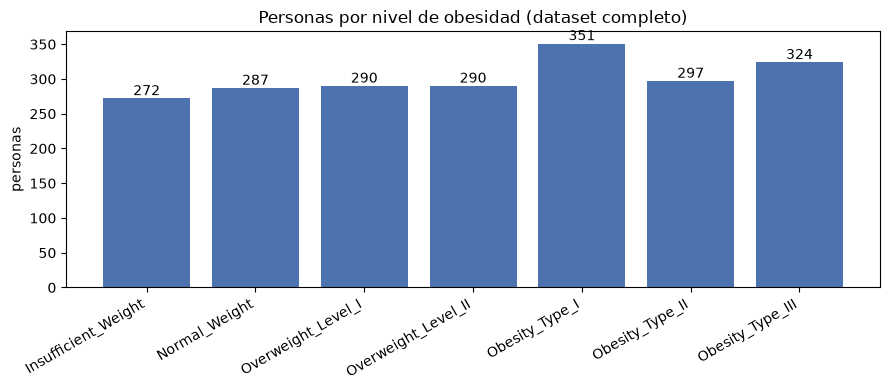

In [45]:
orden_niveles = ["Insufficient_Weight", "Normal_Weight", "Overweight_Level_I",
                 "Overweight_Level_II", "Obesity_Type_I", "Obesity_Type_II", "Obesity_Type_III"]
conteo = df["NObeyesdad"].value_counts().reindex(orden_niveles)
print(pd.DataFrame({"personas": conteo, "%": (conteo / conteo.sum() * 100).round(1)}))

fig, ax = plt.subplots(figsize=(9, 4))
barras = ax.bar(conteo.index, conteo.values, color="#4C72B0")
ax.bar_label(barras)
ax.set_title("Personas por nivel de obesidad (dataset completo)")
ax.set_ylabel("personas")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig("graficas/EA3_niveles_obesidad.png", dpi=120)
plt.show()

### 1.4 · Variable objetivo: regla de construcción

Para la decisión de la EPS lo importante es saber si la persona **tiene obesidad o no**. Por eso se construye una variable binaria a partir de `NObeyesdad`:

- **`obesidad = 1`** si el nivel es `Obesity_Type_I`, `Obesity_Type_II` u `Obesity_Type_III`.
- **`obesidad = 0`** en los demás casos (peso insuficiente, normal o sobrepeso).

**Variables excluidas para evitar fuga de información:**
- `NObeyesdad`, porque es la variable original con la que se construyó el objetivo.
- `Height` y `Weight`, porque el nivel de obesidad del estudio se calculó con el índice de masa corporal (peso / estatura²). Si el modelo las recibiera, "adivinaría" la respuesta con la fórmula en lugar de aprender de los hábitos.

In [46]:
df["obesidad"] = df["NObeyesdad"].isin(
    ["Obesity_Type_I", "Obesity_Type_II", "Obesity_Type_III"]
).astype(int)

print(df["obesidad"].value_counts().rename({0: "sin obesidad", 1: "con obesidad"}))
print("\nProporción con obesidad:", round(df["obesidad"].mean() * 100, 1), "%")

obesidad
sin obesidad    1139
con obesidad     972
Name: count, dtype: int64

Proporción con obesidad: 46.0 %


## 2. Preprocesamiento

### 2.1 · Limpieza y transformación

Se guarda una copia del estado inicial para comparar antes y después.

In [47]:
df_inicial = df.copy()

# 1. Duplicados: filas idénticas que repiten a la misma persona
duplicados = int(df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print(f"1. Duplicados eliminados: {duplicados} | filas: {len(df_inicial)} -> {len(df)}")

# 2. Escalas ordinales: el estudio generó parte de los datos de forma sintética y
#    dejó decimales (por ejemplo, FCVC = 2.45) en preguntas que solo admiten
#    respuestas enteras. Se redondean al valor válido más cercano.
ordinales = {"FCVC": (1, 3), "NCP": (1, 4), "CH2O": (1, 3), "FAF": (0, 3), "TUE": (0, 2)}
for col, (minimo, maximo) in ordinales.items():
    df[col] = df[col].round().clip(minimo, maximo).astype(int)
print("2. Escalas ordinales redondeadas:", list(ordinales))

# 3. Edad entera
df["Age"] = df["Age"].round().astype(int)
print("3. Edad redondeada a años enteros")

# 4. Nombres en español para facilitar la lectura
nombres = {
    "Gender": "genero", "Age": "edad", "Height": "estatura", "Weight": "peso",
    "family_history_with_overweight": "historial_familiar", "FAVC": "comida_calorica",
    "FCVC": "frecuencia_verduras", "NCP": "comidas_principales", "CAEC": "come_entre_comidas",
    "SMOKE": "fuma", "CH2O": "agua", "SCC": "controla_calorias", "FAF": "actividad_fisica",
    "TUE": "tiempo_pantallas", "CALC": "alcohol", "MTRANS": "transporte",
    "NObeyesdad": "nivel_obesidad",
}
df = df.rename(columns=nombres)
print("4. Columnas renombradas al español")

# 5. Variables binarias yes/no -> 1/0
binarias = ["historial_familiar", "comida_calorica", "fuma", "controla_calorias"]
for col in binarias:
    df[col] = (df[col] == "yes").astype(int)
print("5. Variables yes/no convertidas a 1/0:", binarias)

# 6. Variables ordinales de texto -> números en su orden natural
escala_frecuencia = {"no": 0, "Sometimes": 1, "Frequently": 2, "Always": 3}
for col in ["come_entre_comidas", "alcohol"]:
    df[col] = df[col].map(escala_frecuencia).astype(int)
print("6. 'come_entre_comidas' y 'alcohol' convertidas a escala 0-3")

1. Duplicados eliminados: 24 | filas: 2111 -> 2087
2. Escalas ordinales redondeadas: ['FCVC', 'NCP', 'CH2O', 'FAF', 'TUE']
3. Edad redondeada a años enteros
4. Columnas renombradas al español
5. Variables yes/no convertidas a 1/0: ['historial_familiar', 'comida_calorica', 'fuma', 'controla_calorias']
6. 'come_entre_comidas' y 'alcohol' convertidas a escala 0-3


In [48]:
predictoras_num = ["edad", "frecuencia_verduras", "comidas_principales", "agua",
                   "actividad_fisica", "tiempo_pantallas", "come_entre_comidas", "alcohol"]
predictoras_bin = ["historial_familiar", "comida_calorica", "fuma", "controla_calorias"]
predictoras_cat = ["genero", "transporte"]
PREDICTORAS = predictoras_num + predictoras_bin + predictoras_cat
OBJETIVO = "obesidad"
EXCLUIDAS = ["estatura", "peso", "nivel_obesidad"]

print("Predictoras:", PREDICTORAS)
print("Objetivo:", OBJETIVO)
print("Excluidas por fuga de información:", EXCLUIDAS)

originales = df_inicial.drop(columns="obesidad")
antes_despues = pd.DataFrame({
    "antes": [originales.shape[0], originales.shape[1], int(originales.duplicated().sum()),
              int((originales["FCVC"] % 1 != 0).sum()),
              int(originales.select_dtypes(exclude="number").shape[1])],
    "después": [df.shape[0], len(PREDICTORAS) + 1, int(df.duplicated().sum()),
                int((df["frecuencia_verduras"] % 1 != 0).sum()),
                int(df[PREDICTORAS].select_dtypes(exclude="number").shape[1])],
}, index=["filas", "columnas para el modelo", "duplicados",
          "valores decimales en verduras", "columnas de texto"])
antes_despues

Predictoras: ['edad', 'frecuencia_verduras', 'comidas_principales', 'agua', 'actividad_fisica', 'tiempo_pantallas', 'come_entre_comidas', 'alcohol', 'historial_familiar', 'comida_calorica', 'fuma', 'controla_calorias', 'genero', 'transporte']
Objetivo: obesidad
Excluidas por fuga de información: ['estatura', 'peso', 'nivel_obesidad']


,antes,después
filas,2111,2087
columnas para el modelo,17,15
duplicados,24,3
valores decimales en verduras,826,0
columnas de texto,9,2


In [49]:
df[PREDICTORAS + [OBJETIVO]].head()

,edad,frecuencia_verduras,comidas_principales,agua,actividad_fisica,tiempo_pantallas,come_entre_comidas,alcohol,historial_familiar,comida_calorica,fuma,controla_calorias,genero,transporte,obesidad
0,21,3,3,2,2,0,3,1,1,1,1,0,Female,Public_Transportation,0
1,21,3,3,3,1,1,1,1,1,1,0,0,Female,Public_Transportation,1
2,23,1,1,3,0,2,1,1,1,1,0,0,Female,Public_Transportation,1
3,22,3,2,3,1,0,2,0,0,0,0,0,Female,Public_Transportation,0
4,26,3,3,3,2,1,1,1,1,1,0,0,Male,Public_Transportation,1


### 2.2 · Justificación del preprocesamiento

| Operación | Problema que resuelve | Efecto en los datos |
|---|---|---|
| Eliminar duplicados | Personas repetidas que pesarían doble en el modelo y podrían quedar a la vez en entrenamiento y prueba | Menos filas, todas distintas |
| Redondear escalas ordinales | Valores imposibles (por ejemplo, 2,45 comidas) generados al crear datos sintéticos | Cada respuesta vuelve a su escala válida |
| Renombrar columnas | Siglas difíciles de leer (`FAVC`, `CAEC`…) | Resultados más fáciles de interpretar |
| Convertir yes/no y frecuencias a números | Los modelos de scikit-learn solo reciben números | Variables numéricas que conservan su orden natural |
| Excluir `estatura`, `peso` y `nivel_obesidad` | Fuga de información: con ellas el modelo calcula la respuesta en vez de aprenderla de los hábitos | El modelo solo usa información que la EPS puede obtener con una encuesta |

**Pendiente para la parte del modelo:** `genero` y `transporte` se codificarán con *one-hot*, y la decisión de escalar o no depende del algoritmo: los árboles no lo necesitan, pero K-means y KNN sí, porque usan distancias. Esos pasos se ajustarán **solo con el conjunto de entrenamiento** dentro de un `Pipeline`.

## 3. Selección y funcionamiento del modelo

**Tipo de aprendizaje: supervisado (clasificación).** La pregunta tiene una respuesta conocida en los datos: cada persona ya está marcada con o sin obesidad. El modelo aprende de esos ejemplos qué combinación de hábitos acompaña a la obesidad y luego la reconoce en personas nuevas.

- **Variable objetivo:** `obesidad` (1 = con obesidad, 0 = sin obesidad).
- **Variables predictoras:** los 14 hábitos y datos personales de la sección 2 (sin estatura, peso ni nivel de obesidad).

Como en clase, se empieza con un modelo sencillo, se revisan sus resultados y luego se cambia por uno mejor.

### 3.1 · Código mínimo

El flujo en su forma más corta: preparar, dividir, entrenar y medir, con un árbol de decisión.

In [50]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

X = pd.get_dummies(df[PREDICTORAS], columns=predictoras_cat)   # preparar datos
y = df[OBJETIVO]
X_train, X_test, y_train, y_test = train_test_split(                # dividir datos
    X, y, test_size=0.2, random_state=SEMILLA, stratify=y
)
modelo = DecisionTreeClassifier(random_state=SEMILLA)               # inicializar modelo
modelo.fit(X_train, y_train)                                        # entrenar
print("Exactitud en prueba:", round(modelo.score(X_test, y_test), 4))  # evaluar

Exactitud en prueba: 0.8756


### 3.2 · Primer experimento con la clase: árbol de decisión

Cada línea del código mínimo se convirtió en un método de `ClasificadorTabular` (`src/clases_po/clasificador_tabular.py`): `preparar_datos`, `dividir_datos`, `construir_modelo`, `entrenar`, `evaluar` y `ejecutar`.

**Cómo decide un árbol:** busca la pregunta (variable y valor de corte) que mejor separa a las personas con y sin obesidad; divide los datos en dos grupos y repite la búsqueda dentro de cada grupo, hasta llegar a grupos casi puros. Para clasificar a una persona nueva, se recorre el árbol respondiendo las preguntas hasta llegar a una hoja.

In [51]:
from clases_po.clasificador_tabular import ClasificadorTabular

arbol = ClasificadorTabular(
    modelo=DecisionTreeClassifier(random_state=SEMILLA),
    columnas_numericas=predictoras_num + predictoras_bin,
    columnas_categoricas=predictoras_cat,
    columna_objetivo=OBJETIVO,
    escalar=False,
    test_size=0.2,
    random_state=SEMILLA,
)
r_arbol = arbol.ejecutar(df)

[ejecutar][1/6] cargar_datos (DecisionTreeClassifier)
[ejecutar][2/6] preparar_datos
[preparar_datos] 2087 filas válidas; 0 filas eliminadas; clases: {0: 1115, 1: 972}.
[ejecutar][3/6] dividir_datos
[dividir_datos] stratify=y; entrenamiento=1669; prueba=418; random_state=42.
[ejecutar][4/6] construir_modelo
[construir_modelo] numéricas (sin escalar) + one-hot -> DecisionTreeClassifier
[ejecutar][5/6] entrenar
[entrenar] 1669 filas; modelo guardado en modelos/20261027_015238_907346_DecisionTreeClassifier.pkl
[ejecutar][6/6] evaluar
[evaluar] exactitud=0.8756; F1 macro=0.8744; F1 ponderado=0.8753
              precision    recall  f1-score   support

           0     0.8638    0.9103    0.8865       223
           1     0.8907    0.8359    0.8624       195

    accuracy                         0.8756       418
   macro avg     0.8773    0.8731    0.8744       418
weighted avg     0.8764    0.8756    0.8753       418

        pred 0  pred 1
real 0     203      20
real 1      32     163 



### 3.3 · Las preguntas que hace el árbol

Primeros niveles del árbol: cada caja muestra la pregunta, cuántas personas llegan (`samples`) y cuántas hay de cada clase (`value = [sin obesidad, con obesidad]`).

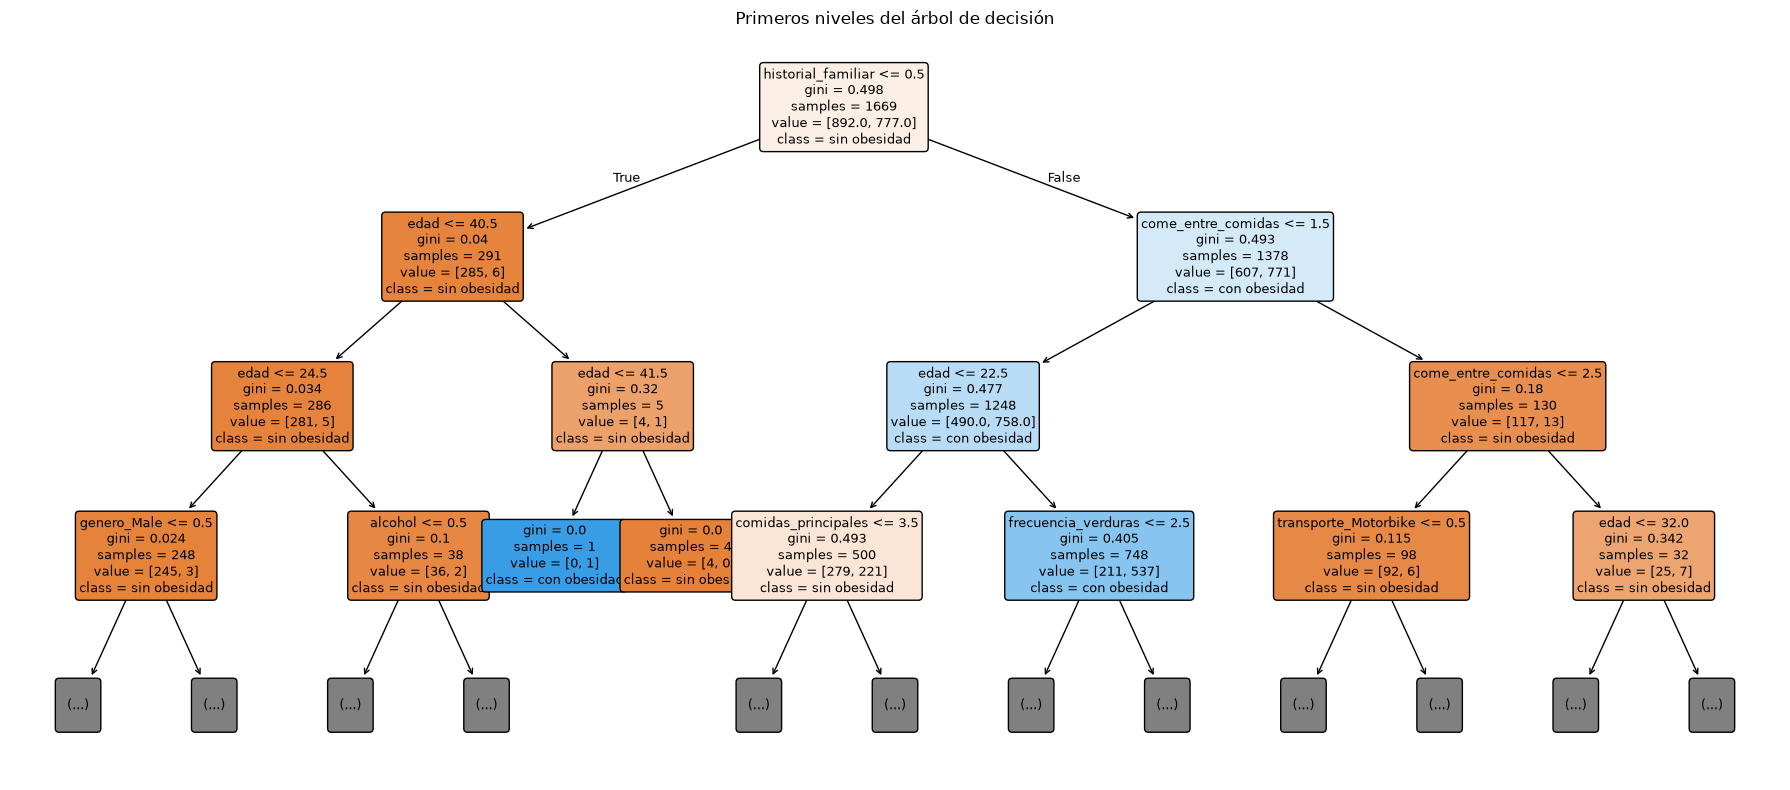

In [52]:
from sklearn.tree import plot_tree

fig, ax = plt.subplots(figsize=(18, 8))
plot_tree(arbol.pipeline.named_steps["modelo"], max_depth=3,
          feature_names=arbol.pipeline.named_steps["prep"].get_feature_names_out(),
          class_names=["sin obesidad", "con obesidad"], filled=True, rounded=True, fontsize=9, ax=ax)
ax.set_title("Primeros niveles del árbol de decisión")
plt.tight_layout()
plt.savefig("graficas/EA3_arbol.png", dpi=120)
plt.show()

### 3.4 · Cambiar de modelo: Random Forest

Un solo árbol sin límite de profundidad **memoriza** el entrenamiento: acierta casi todo con los datos que ya vio, pero se equivoca más con personas nuevas (sobreajuste).

**Random Forest** corrige eso construyendo muchos árboles distintos y haciéndolos votar:

1. Toma una **muestra aleatoria con reemplazo** del entrenamiento (cada árbol ve datos un poco distintos).
2. Construye un árbol con esa muestra, pero en cada división solo puede elegir entre **un subconjunto aleatorio de variables**. Así los árboles no se parecen entre sí.
3. Repite los pasos 1 y 2 `n_estimators` veces.
4. Para una persona nueva, **cada árbol vota** "con obesidad" o "sin obesidad". La probabilidad es la proporción de votos, y gana la mayoría (umbral 0,5).

Los errores de un árbol se compensan con los aciertos de los demás, por eso el bosque sobreajusta menos que un árbol solo.

**Parámetros principales:**
- `n_estimators`: número de árboles. Más árboles dan resultados más estables, pero tardan más.
- `max_depth`: profundidad máxima de cada árbol. Limitarla reduce el sobreajuste.
- `min_samples_leaf`: mínimo de personas en cada hoja. Evita reglas basadas en casos aislados.
- `random_state`: semilla, para obtener siempre el mismo resultado.

Como el árbol, **no necesita escalar** las variables: cada pregunta compara una variable contra un valor de corte.

In [53]:
from sklearn.ensemble import RandomForestClassifier

bosque_base = ClasificadorTabular(
    modelo=RandomForestClassifier(random_state=SEMILLA),
    columnas_numericas=predictoras_num + predictoras_bin,
    columnas_categoricas=predictoras_cat,
    columna_objetivo=OBJETIVO,
    escalar=False,
    test_size=0.2,
    random_state=SEMILLA,
)
r_bosque_base = bosque_base.ejecutar(df)

[ejecutar][1/6] cargar_datos (RandomForestClassifier)
[ejecutar][2/6] preparar_datos
[preparar_datos] 2087 filas válidas; 0 filas eliminadas; clases: {0: 1115, 1: 972}.
[ejecutar][3/6] dividir_datos
[dividir_datos] stratify=y; entrenamiento=1669; prueba=418; random_state=42.
[ejecutar][4/6] construir_modelo
[construir_modelo] numéricas (sin escalar) + one-hot -> RandomForestClassifier
[ejecutar][5/6] entrenar
[entrenar] 1669 filas; modelo guardado en modelos/20261027_015241_784729_RandomForestClassifier.pkl
[ejecutar][6/6] evaluar
[evaluar] exactitud=0.9019; F1 macro=0.9007; F1 ponderado=0.9014
              precision    recall  f1-score   support

           0     0.8760    0.9507    0.9118       223
           1     0.9375    0.8462    0.8895       195

    accuracy                         0.9019       418
   macro avg     0.9068    0.8984    0.9007       418
weighted avg     0.9047    0.9019    0.9014       418

        pred 0  pred 1
real 0     212      11
real 1      30     165 



### 3.5 · Ajuste de parámetros con validación cruzada

Para elegir `n_estimators`, `max_depth` y `min_samples_leaf` con evidencia se comparan varias combinaciones con **validación cruzada de 5 particiones, solo sobre el conjunto de entrenamiento**. El conjunto de prueba se reserva para la evaluación final. La métrica es el F1 de la clase "con obesidad".

In [54]:
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV, StratifiedKFold

validacion = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
rejilla = {
    "modelo__n_estimators": [100, 300],
    "modelo__max_depth": [5, 10, 15, None],
    "modelo__min_samples_leaf": [1, 5],
}
busqueda = GridSearchCV(clone(bosque_base.pipeline), rejilla, cv=validacion, scoring="f1",
                        return_train_score=True, n_jobs=-1)
busqueda.fit(bosque_base.X_train, bosque_base.y_train)

resultados_cv = pd.DataFrame(busqueda.cv_results_)[
    ["param_modelo__n_estimators", "param_modelo__max_depth", "param_modelo__min_samples_leaf",
     "mean_train_score", "mean_test_score", "std_test_score"]
].rename(columns={
    "param_modelo__n_estimators": "n_estimators", "param_modelo__max_depth": "max_depth",
    "param_modelo__min_samples_leaf": "min_samples_leaf", "mean_train_score": "F1 entrenamiento",
    "mean_test_score": "F1 validación", "std_test_score": "desviación",
}).sort_values("F1 validación", ascending=False).round(4)
print(resultados_cv.to_string(index=False))

MEJORES = {clave.replace("modelo__", ""): valor for clave, valor in busqueda.best_params_.items()}
print("\nMejores parámetros:", MEJORES)

 n_estimators max_depth  min_samples_leaf  F1 entrenamiento  F1 validación  desviación
          300        15                 1            0.9868         0.9119      0.0078
          100        15                 1            0.9861         0.9110      0.0096
          300      None                 1            0.9913         0.9106      0.0068
          100      None                 1            0.9913         0.9070      0.0073
          100        10                 1            0.9505         0.8892      0.0133
          300        10                 1            0.9531         0.8884      0.0096
          100      None                 5            0.9098         0.8706      0.0112
          300      None                 5            0.9133         0.8699      0.0128
          300        15                 5            0.9128         0.8693      0.0107
          100        15                 5            0.9105         0.8651      0.0092
          300        10                 5  

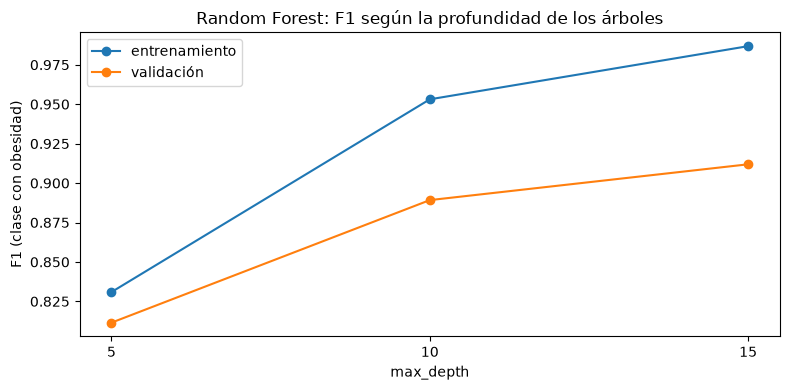

In [55]:
por_profundidad = resultados_cv.assign(max_depth=resultados_cv["max_depth"].astype(str)) \
    .groupby("max_depth", sort=False)[["F1 entrenamiento", "F1 validación"]].max() \
    .reindex(["5", "10", "15", "None"])

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(por_profundidad.index, por_profundidad["F1 entrenamiento"], marker="o", label="entrenamiento")
ax.plot(por_profundidad.index, por_profundidad["F1 validación"], marker="o", label="validación")
ax.set_xlabel("max_depth")
ax.set_ylabel("F1 (clase con obesidad)")
ax.set_title("Random Forest: F1 según la profundidad de los árboles")
ax.legend()
plt.tight_layout()
plt.savefig("graficas/EA3_ajuste_parametros.png", dpi=120)
plt.show()

## 4. Entrenamiento, métricas y evaluación

### 4.1 · Random Forest final con los parámetros elegidos

In [56]:
bosque = ClasificadorTabular(
    modelo=RandomForestClassifier(**MEJORES, random_state=SEMILLA),
    columnas_numericas=predictoras_num + predictoras_bin,
    columnas_categoricas=predictoras_cat,
    columna_objetivo=OBJETIVO,
    escalar=False,
    test_size=0.2,
    random_state=SEMILLA,
)
r_bosque = bosque.ejecutar(df)

[ejecutar][1/6] cargar_datos (RandomForestClassifier)
[ejecutar][2/6] preparar_datos
[preparar_datos] 2087 filas válidas; 0 filas eliminadas; clases: {0: 1115, 1: 972}.
[ejecutar][3/6] dividir_datos
[dividir_datos] stratify=y; entrenamiento=1669; prueba=418; random_state=42.
[ejecutar][4/6] construir_modelo
[construir_modelo] numéricas (sin escalar) + one-hot -> RandomForestClassifier
[ejecutar][5/6] entrenar
[entrenar] 1669 filas; modelo guardado en modelos/20261027_015313_576088_RandomForestClassifier.pkl
[ejecutar][6/6] evaluar
[evaluar] exactitud=0.9139; F1 macro=0.9130; F1 ponderado=0.9136
              precision    recall  f1-score   support

           0     0.8945    0.9507    0.9217       223
           1     0.9392    0.8718    0.9043       195

    accuracy                         0.9139       418
   macro avg     0.9169    0.9112    0.9130       418
weighted avg     0.9154    0.9139    0.9136       418

        pred 0  pred 1
real 0     212      11
real 1      25     170 



### 4.2 · Matriz de confusión

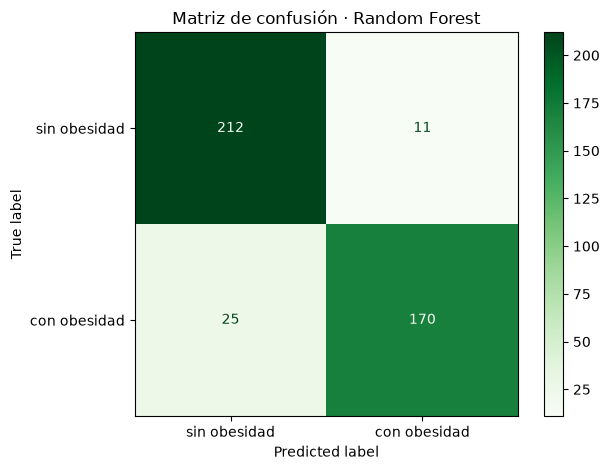

In [57]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    bosque.y_test, r_bosque["predicciones"], labels=[0, 1],
    display_labels=["sin obesidad", "con obesidad"], cmap="Greens", values_format=",d",
)
plt.title("Matriz de confusión · Random Forest")
plt.tight_layout()
plt.savefig("graficas/EA3_matriz_confusion.png", dpi=120)
plt.show()

### 4.3 · Hábitos que más pesan en la decisión

edad                   0.1997
historial_familiar     0.1330
comidas_principales    0.0902
come_entre_comidas     0.0877
actividad_fisica       0.0687
alcohol                0.0685
frecuencia_verduras    0.0557
comida_calorica        0.0551
agua                   0.0549
tiempo_pantallas       0.0507
dtype: float64


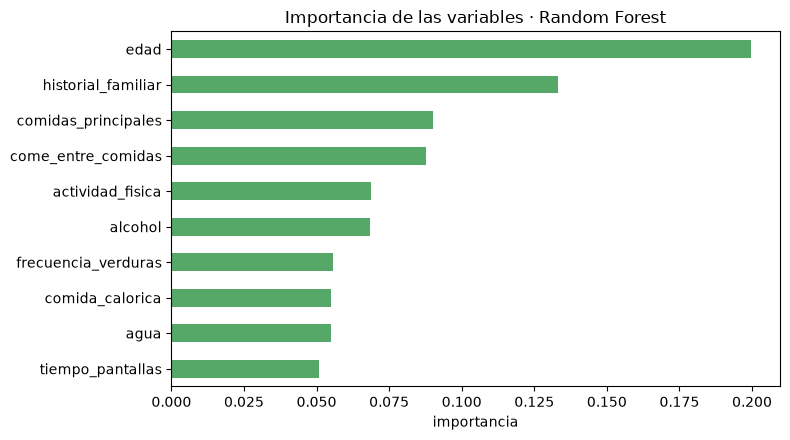

In [58]:
importancia = bosque.importancia_variables(10)
print(importancia.round(4))

fig, ax = plt.subplots(figsize=(8, 4.5))
importancia.sort_values().plot(kind="barh", ax=ax, color="#55A868")
ax.set_title("Importancia de las variables · Random Forest")
ax.set_xlabel("importancia")
plt.tight_layout()
plt.savefig("graficas/EA3_importancia_variables.png", dpi=120)
plt.show()

### 4.4 · Comparación con otros modelos

Se compara el Random Forest final con el árbol del primer experimento y con la regresión logística balanceada vista en clase (que sí necesita escalar).

In [59]:
from sklearn.linear_model import LogisticRegression

def resumen(metricas):
    clase1 = metricas["por_clase"].loc[1]
    return {"exactitud": metricas["exactitud"], "precisión obesidad": clase1["precision"],
            "recall obesidad": clase1["recall"], "F1 obesidad": clase1["f1"], "F1 macro": metricas["f1_macro"]}

logistica = ClasificadorTabular(LogisticRegression(class_weight="balanced", max_iter=1000),
                                predictoras_num + predictoras_bin, predictoras_cat, OBJETIVO,
                                escalar=True, random_state=SEMILLA)
r_logistica = logistica.ejecutar(df)

comparacion_modelos = pd.DataFrame({
    "Árbol de decisión (primer experimento)": resumen(r_arbol["metricas"]),
    "Random Forest (predeterminado)": resumen(r_bosque_base["metricas"]),
    "Random Forest (ajustado)": resumen(r_bosque["metricas"]),
    "Regresión logística balanceada": resumen(r_logistica["metricas"]),
}).T.round(4)
comparacion_modelos

[ejecutar][1/6] cargar_datos (LogisticRegression)
[ejecutar][2/6] preparar_datos
[preparar_datos] 2087 filas válidas; 0 filas eliminadas; clases: {0: 1115, 1: 972}.
[ejecutar][3/6] dividir_datos
[dividir_datos] stratify=y; entrenamiento=1669; prueba=418; random_state=42.
[ejecutar][4/6] construir_modelo
[construir_modelo] numéricas (StandardScaler) + one-hot -> LogisticRegression
[ejecutar][5/6] entrenar
[entrenar] 1669 filas; modelo guardado en modelos/20261027_015314_859222_LogisticRegression.pkl
[ejecutar][6/6] evaluar
[evaluar] exactitud=0.7584; F1 macro=0.7581; F1 ponderado=0.7575
              precision    recall  f1-score   support

           0     0.8389    0.6771    0.7494       223
           1     0.6975    0.8513    0.7667       195

    accuracy                         0.7584       418
   macro avg     0.7682    0.7642    0.7581       418
weighted avg     0.7729    0.7584    0.7575       418

        pred 0  pred 1
real 0     151      72
real 1      29     166 

[ejecutar

,exactitud,precisión obesidad,recall obesidad,F1 obesidad,F1 macro
Árbol de decisión (primer experimento),0.8756,0.8907,0.8359,0.8624,0.8744
Random Forest (predeterminado),0.9019,0.9375,0.8462,0.8895,0.9007
Random Forest (ajustado),0.9139,0.9392,0.8718,0.9043,0.9130
Regresión logística balanceada,0.7584,0.6975,0.8513,0.7667,0.7581


### 4.5 · El umbral también decide

Por defecto, el bosque marca "con obesidad" cuando al menos la mitad de los árboles vota por esa clase (probabilidad ≥ 0,5). Hay que pensar en el **costo de cada error para la EPS**:

- **Falso negativo** (tiene obesidad y el modelo dice que no): la persona queda por fuera del programa. Es el error más costoso.
- **Falso positivo** (no tiene obesidad y el modelo dice que sí): se invita a alguien que no lo necesitaba. Cuesta una llamada o una cita de valoración.

Por eso conviene **priorizar el recall** de la clase "con obesidad", sin que la precisión caiga demasiado.

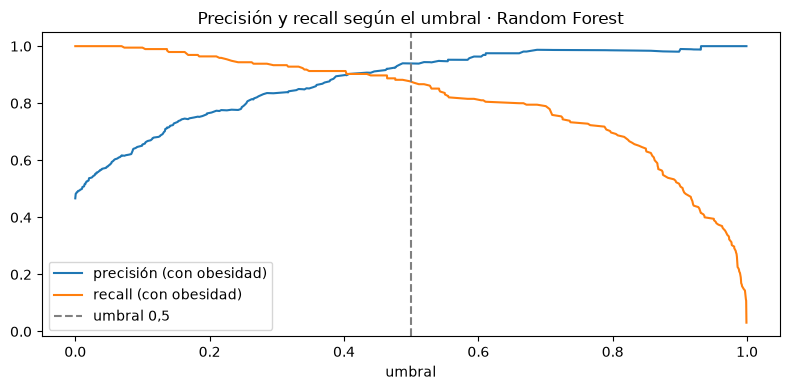

In [60]:
from sklearn.metrics import precision_recall_curve

p_obesidad = bosque.predecir_proba(bosque.X_test)[1].to_numpy()
precision, recall, umbrales = precision_recall_curve(bosque.y_test, p_obesidad)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(umbrales, precision[:-1], label="precisión (con obesidad)")
ax.plot(umbrales, recall[:-1], label="recall (con obesidad)")
ax.axvline(0.5, color="gray", linestyle="--", label="umbral 0,5")
ax.set_xlabel("umbral")
ax.set_title("Precisión y recall según el umbral · Random Forest")
ax.legend()
plt.tight_layout()
plt.savefig("graficas/EA3_umbral.png", dpi=120)
plt.show()

In [61]:
comparacion_umbral = {}
for umbral in [0.3, 0.4, 0.5]:
    print(f"===== umbral = {umbral} =====")
    comparacion_umbral[f"umbral {umbral}"] = resumen(
        bosque.evaluar(bosque.X_test, bosque.y_test, umbral=umbral, clase_umbral=1)
    )
comparacion_umbral = pd.DataFrame(comparacion_umbral).T.round(4)
comparacion_umbral

===== umbral = 0.3 =====
[evaluar] exactitud=0.8852; F1 macro=0.8851; F1 ponderado=0.8853
              precision    recall  f1-score   support

           0     0.9353    0.8430    0.8868       223
           1     0.8387    0.9333    0.8835       195

    accuracy                         0.8852       418
   macro avg     0.8870    0.8882    0.8851       418
weighted avg     0.8903    0.8852    0.8853       418

        pred 0  pred 1
real 0     188      35
real 1      13     182 

===== umbral = 0.4 =====
[evaluar] exactitud=0.9115; F1 macro=0.9112; F1 ponderado=0.9115
              precision    recall  f1-score   support

           0     0.9227    0.9103    0.9165       223
           1     0.8990    0.9128    0.9059       195

    accuracy                         0.9115       418
   macro avg     0.9109    0.9116    0.9112       418
weighted avg     0.9117    0.9115    0.9115       418

        pred 0  pred 1
real 0     203      20
real 1      17     178 

===== umbral = 0.5 =====

,exactitud,precisión obesidad,recall obesidad,F1 obesidad,F1 macro
umbral 0.3,0.8852,0.8387,0.9333,0.8835,0.8851
umbral 0.4,0.9115,0.8990,0.9128,0.9059,0.9112
umbral 0.5,0.9139,0.9392,0.8718,0.9043,0.9130


### 4.6 · Umbral recomendado

**Regla:** entre los umbrales evaluados, se elige el que logra el **mayor recall** de la clase "con obesidad" manteniendo una **precisión de al menos 0,85** (es decir, de cada 100 personas invitadas, al menos 85 sí lo necesitan). Si hay empate, se elige el umbral más alto. Si ningún umbral alcanza esa precisión, se elige el de mayor F1.

Umbral recomendado: 0.4
[evaluar] exactitud=0.9115; F1 macro=0.9112; F1 ponderado=0.9115
              precision    recall  f1-score   support

           0     0.9227    0.9103    0.9165       223
           1     0.8990    0.9128    0.9059       195

    accuracy                         0.9115       418
   macro avg     0.9109    0.9116    0.9112       418
weighted avg     0.9117    0.9115    0.9115       418

        pred 0  pred 1
real 0     203      20
real 1      17     178 



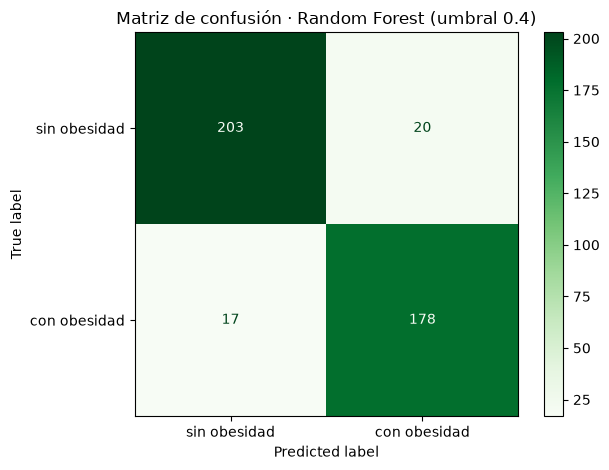

In [62]:
PRECISION_MINIMA = 0.85
tabla_umbral = comparacion_umbral.assign(umbral=[float(i.split()[-1]) for i in comparacion_umbral.index])
candidatos = tabla_umbral[tabla_umbral["precisión obesidad"] >= PRECISION_MINIMA]
if candidatos.empty:
    # Ningún umbral alcanza la precisión mínima: se usa el de mejor F1
    print("Ningún umbral alcanza la precisión mínima; se elige el de mayor F1.")
    REGLA_UMBRAL = f"ningún umbral alcanzó precisión >= {PRECISION_MINIMA}; se eligió el de mayor F1"
    UMBRAL_RECOMENDADO = float(tabla_umbral.sort_values(["F1 obesidad", "umbral"], ascending=False)["umbral"].iloc[0])
else:
    REGLA_UMBRAL = f"mayor recall con precisión >= {PRECISION_MINIMA}"
    UMBRAL_RECOMENDADO = float(candidatos.sort_values(["recall obesidad", "umbral"], ascending=False)["umbral"].iloc[0])
print("Umbral recomendado:", UMBRAL_RECOMENDADO)

metricas_finales = bosque.evaluar(bosque.X_test, bosque.y_test, umbral=UMBRAL_RECOMENDADO, clase_umbral=1)

ConfusionMatrixDisplay.from_predictions(
    bosque.y_test, bosque.predicciones, labels=[0, 1],
    display_labels=["sin obesidad", "con obesidad"], cmap="Greens", values_format=",d",
)
plt.title(f"Matriz de confusión · Random Forest (umbral {UMBRAL_RECOMENDADO})")
plt.tight_layout()
plt.savefig("graficas/EA3_matriz_confusion_umbral.png", dpi=120)
plt.show()

## 5. Resumen automático

El archivo `reportes/EA3_resumen_modelo.txt` se genera con los resultados de esta ejecución: no se escribe a mano.

In [63]:
from datetime import datetime

def tabla(df_tabla):
    return df_tabla.to_string()

matriz_final = metricas_finales["matriz"]
fn = int(matriz_final.loc["real 1", "pred 0"])
fp = int(matriz_final.loc["real 0", "pred 1"])
clase1 = metricas_finales["por_clase"].loc[1]

lineas = [
    "RESUMEN AUTOMÁTICO - EA3 APRENDIZAJE SUPERVISADO",
    "=" * 70,
    f"Fecha de ejecución: {datetime.now():%Y-%m-%d %H:%M:%S}",
    "",
    "1. PREGUNTA DE NEGOCIO",
    "¿Qué hábitos de alimentación y de actividad física permiten identificar a las",
    "personas con obesidad, para que una EPS priorice a quién incluir en sus programas",
    "de prevención y acompañamiento nutricional?",
    "",
    "2. DATASET",
    f"Identificador: {DATASET}",
    f"Enlace: https://huggingface.co/datasets/{DATASET}",
    f"Splits unidos: train ({len(df_train)} filas) + test ({len(df_test)} filas) = {len(df_inicial)} filas",
    "",
    "3. PREPROCESAMIENTO",
    f"- Duplicados eliminados: {duplicados} (filas finales: {len(df)}).",
    f"- Escalas ordinales redondeadas a valores válidos: {', '.join(ordinales)}.",
    "- Edad redondeada a años enteros; columnas renombradas al español.",
    f"- Variables yes/no convertidas a 1/0: {', '.join(predictoras_bin)}.",
    "- 'come_entre_comidas' y 'alcohol' convertidas a escala 0-3.",
    f"- Categóricas codificadas con one-hot dentro del Pipeline: {', '.join(predictoras_cat)}.",
    "- Sin escalado: Random Forest compara cada variable contra un valor de corte.",
    f"- Excluidas por fuga de información: {', '.join(EXCLUIDAS)}.",
    "- Objetivo: obesidad = 1 si el nivel es Obesity_Type_I, II o III; 0 en otro caso.",
    f"- Proporción con obesidad: {df[OBJETIVO].mean() * 100:.1f} %.",
    "",
    "4. MODELO",
    "Tipo de aprendizaje: supervisado (clasificación binaria).",
    "Algoritmo: RandomForestClassifier (scikit-learn), dentro de un Pipeline.",
    f"Variables predictoras ({len(PREDICTORAS)}): {', '.join(PREDICTORAS)}.",
    f"Variable objetivo: {OBJETIVO}.",
    f"Parámetros elegidos por validación cruzada: {MEJORES}; random_state={SEMILLA}.",
    f"Configuración: test_size=0.2, stratify=y, entrenamiento={len(bosque.X_train)}, prueba={len(bosque.X_test)}.",
    f"Validación cruzada: StratifiedKFold de 5 particiones sobre entrenamiento, métrica F1;",
    f"  F1 de validación del mejor modelo = {busqueda.best_score_:.4f}.",
    "",
    "5. MÉTRICAS EN EL CONJUNTO DE PRUEBA",
    "Comparación de modelos (umbral 0,5):",
    tabla(comparacion_modelos),
    "",
    "Random Forest según el umbral:",
    tabla(comparacion_umbral),
    "",
    f"Umbral recomendado: {UMBRAL_RECOMENDADO} ({REGLA_UMBRAL}).",
    f"  Exactitud: {metricas_finales['exactitud']:.4f}",
    f"  Precisión (con obesidad): {clase1['precision']:.4f}",
    f"  Recall (con obesidad): {clase1['recall']:.4f}",
    f"  F1 (con obesidad): {clase1['f1']:.4f}",
    "  Matriz de confusión:",
    tabla(matriz_final),
    "",
    "Variables más importantes (Random Forest):",
    tabla(importancia.head(5).round(4).to_frame("importancia")),
    "",
    "6. INTERPRETACIÓN Y LIMITACIONES",
    f"- Con el umbral recomendado, el modelo detecta {clase1['recall'] * 100:.0f} de cada 100 personas con obesidad;",
    f"  de cada 100 que marca como 'con obesidad', {clase1['precision'] * 100:.0f} lo son.",
    f"- En la prueba quedaron por fuera {fn} personas con obesidad (falsos negativos) y se marcaron",
    f"  {fp} personas sin obesidad (falsos positivos).",
    f"- Las variables con más peso son {importancia.index[0]} y {importancia.index[1]}, seguidas de",
    f"  {', '.join(importancia.index[2:6])}.",
    "- El modelo muestra asociaciones, no causas. Los hábitos son autodeclarados.",
    "- Según el estudio original, cerca del 77 % de los registros se generó de forma sintética",
    "  para balancear las clases; los resultados deben validarse con datos reales de la EPS.",
    "- La importancia por impureza favorece variables con muchos valores distintos (como la edad).",
]
texto = "\n".join(lineas)
ruta_resumen = Path("reportes/EA3_resumen_modelo.txt")
ruta_resumen.write_text(texto + "\n", encoding="utf-8")
print(texto)
print("\nResumen guardado en:", ruta_resumen.resolve())

RESUMEN AUTOMÁTICO - EA3 APRENDIZAJE SUPERVISADO
Fecha de ejecución: 2026-10-27 01:53:16

1. PREGUNTA DE NEGOCIO
¿Qué hábitos de alimentación y de actividad física permiten identificar a las
personas con obesidad, para que una EPS priorice a quién incluir en sus programas
de prevención y acompañamiento nutricional?

2. DATASET
Identificador: naabiil/Obesity_Levels_Estimation
Enlace: https://huggingface.co/datasets/naabiil/Obesity_Levels_Estimation
Splits unidos: train (1688 filas) + test (423 filas) = 2111 filas

3. PREPROCESAMIENTO
- Duplicados eliminados: 24 (filas finales: 2087).
- Escalas ordinales redondeadas a valores válidos: FCVC, NCP, CH2O, FAF, TUE.
- Edad redondeada a años enteros; columnas renombradas al español.
- Variables yes/no convertidas a 1/0: historial_familiar, comida_calorica, fuma, controla_calorias.
- 'come_entre_comidas' y 'alcohol' convertidas a escala 0-3.
- Categóricas codificadas con one-hot dentro del Pipeline: genero, transporte.
- Sin escalado: Random Fo